# Phase 1: Classifier (ResNet18)

Classify each scan as **normal**, **benign** or **malignant** by fine-tuning a ResNet18 pretrained on ImageNet.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output:** everything is saved to `outputs/classifier/`, ready for the Streamlit app:

| File | What it contains |
| ---- | ---------------- |
| `model_fold0.pt` … `model_fold4.pt` | The 5 trained models (v3: one per cross-validation fold); the app averages them |
| `config.json` | Classes, image size, normalisation, **malignant threshold**, model files and training settings |
| `history.csv` | Loss and accuracy for every epoch of every fold |
| `metrics.json` | Test results (v3), with 95% confidence ranges |
| `metrics_by_version.csv` | v1, v2 and v3 test results side by side, on the same test images |
| `single_vs_ensemble.csv` | Each of the 5 models on its own vs their average |
| `test_predictions.csv` | Prediction and probabilities for every test image |
| `oof_predictions.csv` | Out-of-fold prediction for every cross-validation image (used to tune the threshold) |
| `training_curves.png`, `threshold_tuning.png`, `confusion_matrix.png`, `roc_curves.png`, `gradcam_examples.png` | Result plots |

**Before the first run:** install torchvision with `.env/bin/pip install torchvision`. The pretrained weights download automatically the first time (about 45 MB).

---

### v2 changes (kept)

| Change | Why |
| ------ | --- |
| **Malignant threshold:** malignant if P(malignant) ≥ a tuned threshold | v1 missed 7 of 30 cancers even though the malignant ROC-AUC was 0.95 |
| **95% confidence ranges** (bootstrap) and versions side by side | The test set is small, so we need to see how much of a change is luck |

### v3 changes

| Change | Why |
| ------ | --- |
| **New data split** from `00_clean_data` v3: look-alike duplicates removed, test set frozen to the v1 test images (102 left) | Conflicting duplicates (e.g. `malignant (52)` = `benign (164)`) and train/test look-alikes |
| **5-fold cross-validation:** 5 models, each trained on 4 folds with early stopping on the 5th | Every cross-validation image gets a prediction from a model that **didn't** see it (*out-of-fold*) |
| **Threshold tuned on the out-of-fold predictions** (567 images) instead of the validation set (104) | In v2 the validation set was also used for early stopping, so it was optimistic and tuned thresholds didn't carry over to the test set |
| **Ensemble:** the test prediction is the average of the 5 models | Usually more accurate and more stable than any single model |
| **v1, v2 and v3 scored on the same 102 test images** (v1 / v2 from the archived predictions) | A fair comparison now that 2 test images were removed |

v1 and v2 are archived in `outputs/archive/` and git tags `v1-baseline`, `v2-postprocessing`.

## 1. Imports

In [62]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)

## 2. Settings

In [63]:
DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs/classifier')        # everything the Streamlit app needs is saved here
ARCHIVE_DIR = Path('outputs/archive')          # v1 and v2 results, used for the comparison
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']    # class numbers 0, 1, 2
IMAGE_SIZE = 256         # every scan is padded and resized to 256 x 256
BATCH_SIZE = 16
EPOCHS = 30              # maximum per model; training can stop earlier
LEARNING_RATE = 1e-4     # small, because we fine-tune a pretrained model
PATIENCE = 7             # stop if validation loss hasn't improved for this many epochs
RANDOM_STATE = 42

TRAIN = True                    # v3: True = train the 5 fold models, False = reuse the saved ones
TARGET_MALIGNANT_RECALL = 0.90  # v2: the malignant threshold is tuned to reach this recall
N_BOOTSTRAP = 1000              # v2: resamples used for the 95% confidence ranges

IMAGENET_MEAN = [0.485, 0.456, 0.406]          # the pretrained ResNet expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]


def set_seed(seed):
    """Same random numbers every run (v3: called once per fold, with a different seed per fold)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device, '| Train new models:', TRAIN)

Using device: mps | Train new models: True


## 3. Load the manifest

**v3:** the images are split into a **test set** (102 images, never used for training or tuning) and **5 cross-validation folds** (the other 567 images). Each fold is used once for early stopping while the other 4 train the model.

In [64]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

pool_df = df[df['fold'] >= 0].reset_index(drop=True)           # v3: the 5 cross-validation folds
test_df = df[df['split'] == 'test'].reset_index(drop=True)
N_FOLDS = pool_df['fold'].nunique()

print(f'Cross-validation: {len(pool_df)} images in {N_FOLDS} folds  |  Test: {len(test_df)}')
pd.crosstab(pool_df['label'], pool_df['fold'], margins=True)

Cross-validation: 567 images in 5 folds  |  Test: 102


fold,0,1,2,3,4,All
label,,,,,,
benign,61,61,61,62,62,307
malignant,34,34,34,34,34,170
normal,18,18,18,18,18,90
All,113,113,113,114,114,567


## 4. Image preprocessing

Every scan goes through the same steps:
1. **Grayscale:** ultrasound has no colour.
2. **Pad to a square, then resize to 256 x 256:** black borders are added instead of stretching, so lesion shapes aren't distorted.
3. **Copy to 3 channels:** the pretrained ResNet expects RGB input.
4. **Normalise** with the ImageNet mean and standard deviation.

Training images also get small **random changes** (augmentation), so the model sees a slightly different version every epoch and overfits less. Vertical flips are never used, because the skin is always at the top of an ultrasound scan.

In [65]:
def pad_to_square(image):
    """Convert to grayscale and fit into IMAGE_SIZE x IMAGE_SIZE with black borders (no stretching)."""
    return ImageOps.pad(image.convert('L'), (IMAGE_SIZE, IMAGE_SIZE), color=0)


# Training: random changes so the model sees a slightly different image every epoch
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),                                              # left-right flip only
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    transforms.ColorJitter(brightness=0.2, contrast=0.2),                           # small brightness/contrast changes
    transforms.Grayscale(num_output_channels=3),                                    # 1 channel -> 3 channels
    transforms.ToTensor(),                                                          # PIL image -> tensor (0 to 1)
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation, test and the app: no random changes
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [66]:
class ScanDataset(Dataset):
    """Gives (image tensor, class number) for each row of the manifest."""

    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']))
        return self.transform(image), row['target']


def make_loader(frame, train=False):
    """v3: a DataLoader for any part of the data. Training loaders shuffle and augment; others keep the order."""
    transform = train_transform if train else eval_transform
    return DataLoader(ScanDataset(frame, transform), batch_size=BATCH_SIZE, shuffle=train)

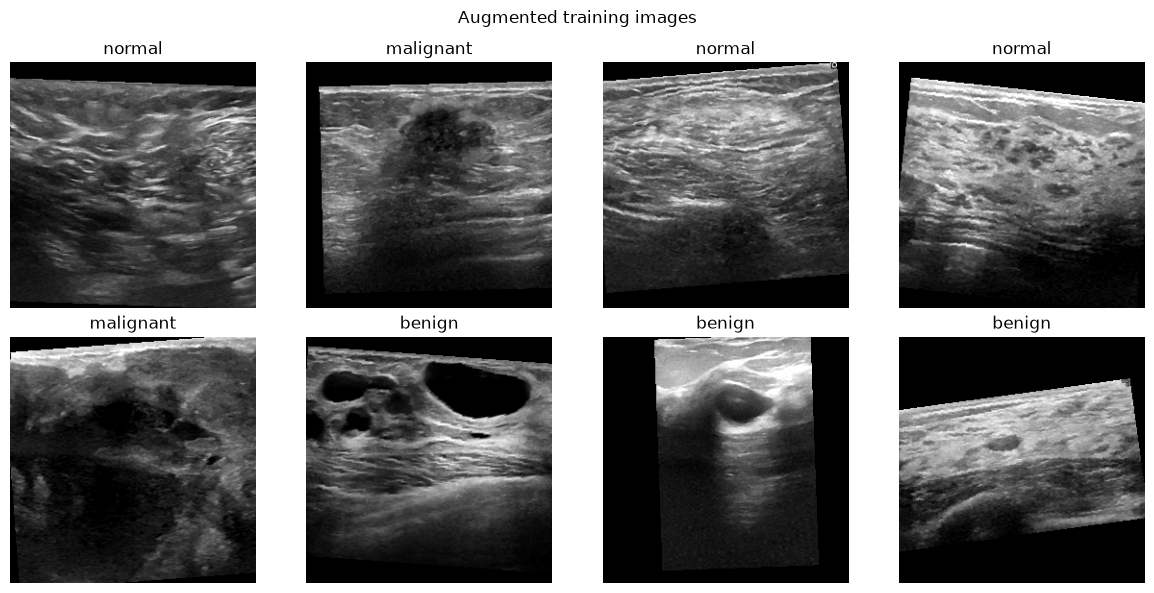

In [67]:
# Look at one batch of augmented training images
images, targets = next(iter(make_loader(pool_df, train=True)))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, target in zip(axes.flat, images, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation to display
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images')
plt.tight_layout()
plt.show()

## 5. Model and loss

We take a ResNet18 already trained on ImageNet and replace its last layer (1000 ImageNet classes) with a new one that has 3 outputs.

Benign images outnumber normal ones by about 3 to 1, so the loss uses **class weights**: mistakes on rarer classes cost more. **v3:** each fold model gets a fresh pretrained ResNet18 and its own class weights.

In [68]:
def build_model(pretrained=True):
    """ResNet18 with a new last layer for 3 classes (ImageNet weights unless pretrained=False)."""
    net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
    net.fc = nn.Linear(net.fc.in_features, len(CLASSES))           # new last layer: 512 features -> 3 classes
    return net.to(device)


def class_weights_for(frame):
    """Rarer classes get a bigger weight in the loss."""
    counts = frame['target'].value_counts().reindex(range(len(CLASSES)), fill_value=0)
    return torch.tensor(len(frame) / (len(CLASSES) * counts.values), dtype=torch.float32)


print('Class weights (all cross-validation images):', dict(zip(CLASSES, class_weights_for(pool_df).numpy().round(2).tolist())))

Class weights (all cross-validation images): {'normal': 2.0999999046325684, 'benign': 0.6200000047683716, 'malignant': 1.1100000143051147}


## 6. Train: 5-fold cross-validation (v3)

For each fold `k` (0 to 4):
1. a fresh pretrained ResNet18 trains on the **other 4 folds**;
2. after every epoch it's checked on **fold k**; the best epoch is saved to `model_fold{k}.pt`, and training stops early after `PATIENCE` epochs without improvement.

This trains 5 models, so it takes about 5 times as long as one model.

With `TRAIN = False`, training is skipped and the saved `model_fold*.pt` files and `history.csv` are reused.

In [69]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    """One pass over the data. Trains when an optimizer is given, otherwise only evaluates. Returns (loss, accuracy)."""
    train = optimizer is not None
    model.train(train)                                 # train mode or evaluation mode
    total_loss, correct = 0.0, 0

    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)

        with torch.set_grad_enabled(train):            # only track gradients when training
            logits = model(images)
            loss = loss_fn(logits, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(targets)
        correct += (logits.argmax(dim=1) == targets).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def train_fold(fold):
    """v3: train one model on the other folds, with early stopping on this fold. Saves model_fold{fold}.pt."""
    set_seed(RANDOM_STATE + fold)
    train_part = pool_df[pool_df['fold'] != fold]
    val_part = pool_df[pool_df['fold'] == fold]

    model = build_model()
    loss_fn = nn.CrossEntropyLoss(weight=class_weights_for(train_part).to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader, val_loader = make_loader(train_part, train=True), make_loader(val_part)

    history, best_val_loss, best_epoch, epochs_without_improvement = [], float('inf'), 0, 0
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, loss_fn)
        history.append({'fold': fold, 'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
                        'val_loss': val_loss, 'val_acc': val_acc})

        if val_loss < best_val_loss:                         # new best: save this model
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            torch.save(model.state_dict(), OUTPUT_DIR / f'model_fold{fold}.pt')
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    print(f'Fold {fold}: {epoch} epochs, best epoch {best_epoch} '
          f'(val loss {best_val_loss:.4f}, val acc {history[best_epoch - 1]["val_acc"]:.3f})')
    return pd.DataFrame(history), best_epoch

In [70]:
if TRAIN:
    histories, best_epochs = [], []
    for fold in range(N_FOLDS):
        fold_history, best = train_fold(fold)
        histories.append(fold_history)
        best_epochs.append(best)
    history = pd.concat(histories, ignore_index=True)
    history.to_csv(OUTPUT_DIR / 'history.csv', index=False)
    (OUTPUT_DIR / 'model.pt').unlink(missing_ok=True)      # v3: replaced by model_fold*.pt (the v2 model is archived)
else:
    # Reuse the saved fold models, history and settings (nothing is retrained)
    previous_config = json.loads((OUTPUT_DIR / 'config.json').read_text())
    history = pd.read_csv(OUTPUT_DIR / 'history.csv')
    best_epochs = previous_config['best_epochs']
    print(f"Skipping training: reusing the {N_FOLDS} fold models (trained on {previous_config['trained_on']})")

Fold 0: 14 epochs, best epoch 7 (val loss 0.4610, val acc 0.894)
Fold 1: 19 epochs, best epoch 12 (val loss 0.2368, val acc 0.903)
Fold 2: 11 epochs, best epoch 4 (val loss 0.6119, val acc 0.788)
Fold 3: 11 epochs, best epoch 4 (val loss 0.3702, val acc 0.842)
Fold 4: 9 epochs, best epoch 2 (val loss 0.5102, val acc 0.798)


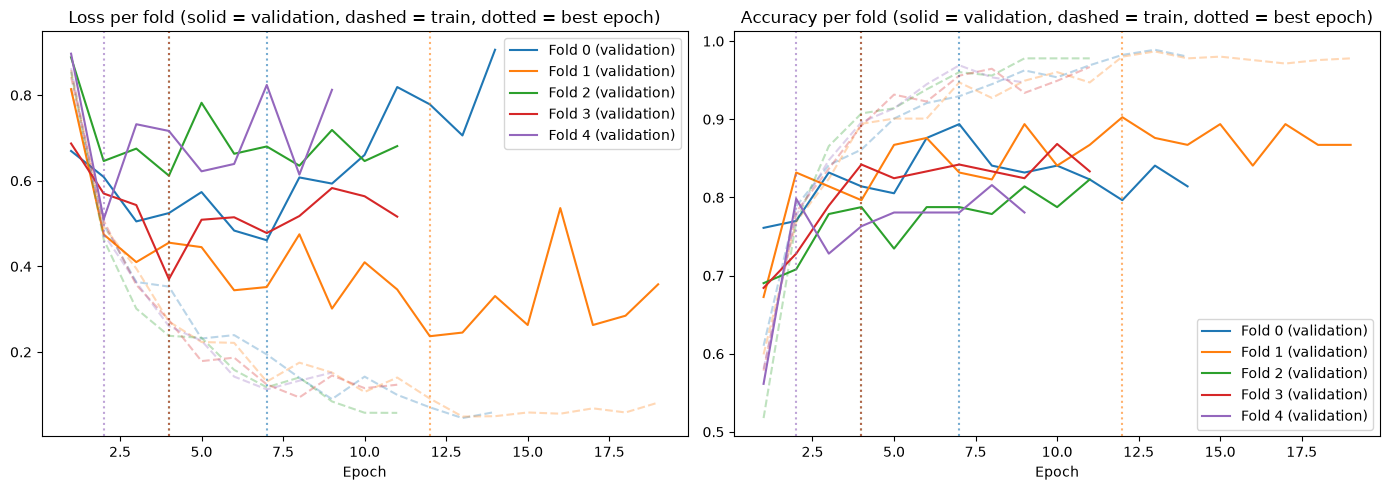

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for fold, fold_history in history.groupby('fold'):
    for ax, metric in zip(axes, ['loss', 'acc']):
        line, = ax.plot(fold_history['epoch'], fold_history[f'val_{metric}'], label=f'Fold {fold} (validation)')
        ax.plot(fold_history['epoch'], fold_history[f'train_{metric}'], color=line.get_color(), alpha=0.3, linestyle='--')
        ax.axvline(best_epochs[fold], color=line.get_color(), linestyle=':', alpha=0.6)

for ax, title in zip(axes, ['Loss', 'Accuracy']):
    ax.set_xlabel('Epoch')
    ax.set_title(f'{title} per fold (solid = validation, dashed = train, dotted = best epoch)')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Predictions: out-of-fold and ensemble (v3)

| Images | Predicted by | Used for |
| ------ | ------------ | -------- |
| **Cross-validation images** (567) | The fold model that **didn't** train on that image (*out-of-fold*) | Tuning the malignant threshold |
| **Test images** (102) | All 5 fold models; their probabilities are **averaged** (*ensemble*) | The final test results |

**Turning probabilities into a class** (v2 rule): malignant if P(malignant) ≥ the tuned threshold, otherwise the more likely of normal / benign.

In [72]:
fold_models = []
for fold in range(N_FOLDS):
    net = build_model(pretrained=False)
    net.load_state_dict(torch.load(OUTPUT_DIR / f'model_fold{fold}.pt', map_location=device))
    net.eval()
    fold_models.append(net)


def get_probs(model, frame):
    """Class probabilities for every image in a frame: one row per image, [P(normal), P(benign), P(malignant)]."""
    all_probs = []
    with torch.no_grad():
        for images, _ in make_loader(frame):
            all_probs.append(torch.softmax(model(images.to(device)), dim=1).cpu())   # scores -> probabilities
    return torch.cat(all_probs).numpy()


def decide(probs, malignant_threshold=None):
    """Turn probabilities into class numbers.
    No threshold: the most likely class. With a threshold (v2): malignant if P(malignant) >= threshold,
    otherwise the more likely of normal / benign."""
    if malignant_threshold is None:
        return probs.argmax(axis=1)
    return np.where(probs[:, 2] >= malignant_threshold, 2, probs[:, :2].argmax(axis=1))


# Out-of-fold: each cross-validation image is predicted by the model that didn't train on it
oof_probs = np.zeros((len(pool_df), len(CLASSES)))
for fold, net in enumerate(fold_models):
    in_fold = (pool_df['fold'] == fold).values
    oof_probs[in_fold] = get_probs(net, pool_df[in_fold])

# Test: every fold model, then their average (the ensemble)
fold_test_probs = np.stack([get_probs(net, test_df) for net in fold_models])     # (5 models, test images, 3)
probs = fold_test_probs.mean(axis=0)

y_oof_true = pool_df['target'].values
y_true = test_df['target'].values
print(f'Out-of-fold predictions: {len(oof_probs)} images  |  Test predictions: {len(probs)} images x {N_FOLDS} models')

Out-of-fold predictions: 567 images  |  Test predictions: 102 images x 5 models


### Tune the malignant threshold on the out-of-fold predictions

For each threshold from 0.05 to 0.50 we measure malignant **recall** (cancers caught) and **precision** (how many "malignant" calls are right) on the **567 out-of-fold predictions**. We pick the **highest** threshold that still reaches `TARGET_MALIGNANT_RECALL`: this catches enough cancers with the fewest false alarms.

**v3:** out-of-fold predictions come from models that never trained on (or early-stopped on) those images, so unlike the v2 validation set they aren't optimistic. With about 170 cancers instead of 31, the threshold is also much more stable.

Chosen malignant threshold: 0.24  (out-of-fold recall 0.900, precision 0.718, 170 cancers)


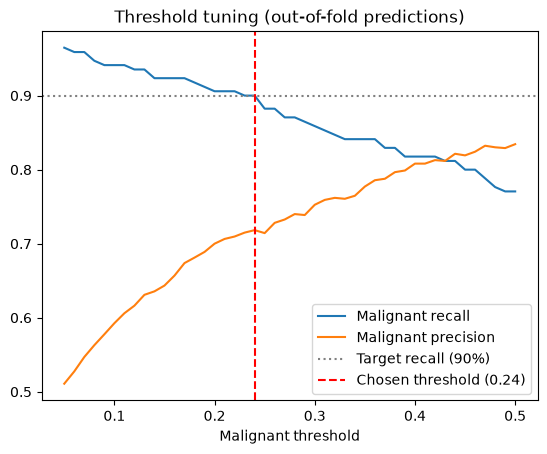

In [73]:
oof_is_malignant = y_oof_true == 2
rows = []
for threshold in np.round(np.arange(0.05, 0.51, 0.01), 2):
    pred = decide(oof_probs, threshold)
    caught = ((pred == 2) & oof_is_malignant).sum()
    rows.append({'threshold': threshold,
                 'recall': caught / oof_is_malignant.sum(),             # % of cancers caught
                 'precision': caught / max((pred == 2).sum(), 1)})      # % of 'malignant' calls that are right
tuning = pd.DataFrame(rows)

# Highest threshold that still reaches the target recall = the fewest false alarms
meets_target = tuning[tuning['recall'] >= TARGET_MALIGNANT_RECALL]
if len(meets_target):
    MALIGNANT_THRESHOLD = float(meets_target['threshold'].max())
else:
    MALIGNANT_THRESHOLD = float(tuning.loc[tuning['recall'].idxmax(), 'threshold'])
    print(f'Target recall {TARGET_MALIGNANT_RECALL:.0%} not reached: using the threshold with the best recall')

chosen = tuning[tuning['threshold'] == MALIGNANT_THRESHOLD].iloc[0]
print(f"Chosen malignant threshold: {MALIGNANT_THRESHOLD:.2f}  "
      f"(out-of-fold recall {chosen['recall']:.3f}, precision {chosen['precision']:.3f}, "
      f"{oof_is_malignant.sum()} cancers)")

plt.plot(tuning['threshold'], tuning['recall'], label='Malignant recall')
plt.plot(tuning['threshold'], tuning['precision'], label='Malignant precision')
plt.axhline(TARGET_MALIGNANT_RECALL, color='grey', linestyle=':', label=f'Target recall ({TARGET_MALIGNANT_RECALL:.0%})')
plt.axvline(MALIGNANT_THRESHOLD, color='red', linestyle='--', label=f'Chosen threshold ({MALIGNANT_THRESHOLD:.2f})')
plt.xlabel('Malignant threshold')
plt.title('Threshold tuning (out-of-fold predictions)')
plt.legend()
plt.savefig(OUTPUT_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
plt.show()

# Save the out-of-fold predictions (useful later, e.g. for a model that combines several outputs)
oof = pool_df[['image_path', 'label', 'fold']].copy()
for i, class_name in enumerate(CLASSES):
    oof[f'prob_{class_name}'] = oof_probs[:, i].round(4)
oof['predicted'] = [CLASSES[i] for i in decide(oof_probs, MALIGNANT_THRESHOLD)]
oof.to_csv(OUTPUT_DIR / 'oof_predictions.csv', index=False)

## 8. Evaluate on the test set

In [74]:
y_pred = decide(probs, MALIGNANT_THRESHOLD)            # v3: ensemble + tuned threshold

# Save every test prediction (used by the app to show results)
results = test_df[['image_path', 'label', 'has_markers']].copy()
for i, class_name in enumerate(CLASSES):
    results[f'prob_{class_name}'] = probs[:, i].round(4)
results['predicted'] = [CLASSES[i] for i in y_pred]
results['correct'] = results['predicted'] == results['label']
results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

print(f'v3: ensemble of {N_FOLDS} models, malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

v3: ensemble of 5 models, malignant if P(malignant) >= 0.24
              precision    recall  f1-score   support

      normal      1.000     0.647     0.786        17
      benign      0.923     0.842     0.881        57
   malignant      0.667     0.929     0.776        28

    accuracy                          0.833       102
   macro avg      0.863     0.806     0.814       102
weighted avg      0.866     0.833     0.836       102



### v1, v2 and v3 on the same test images

v1 and v2 are rescored from their archived predictions, using only the 102 test images that are still in the test set, so all three versions are compared on exactly the same images.

| Version | Model | Decision rule |
| ------- | ----- | ------------- |
| v1 | One model (old split) | Most likely class |
| v2 | Same model | Malignant threshold tuned on the validation set (0.35) |
| v3 | 5 fold models, averaged (new split) | Malignant threshold tuned on the out-of-fold predictions |

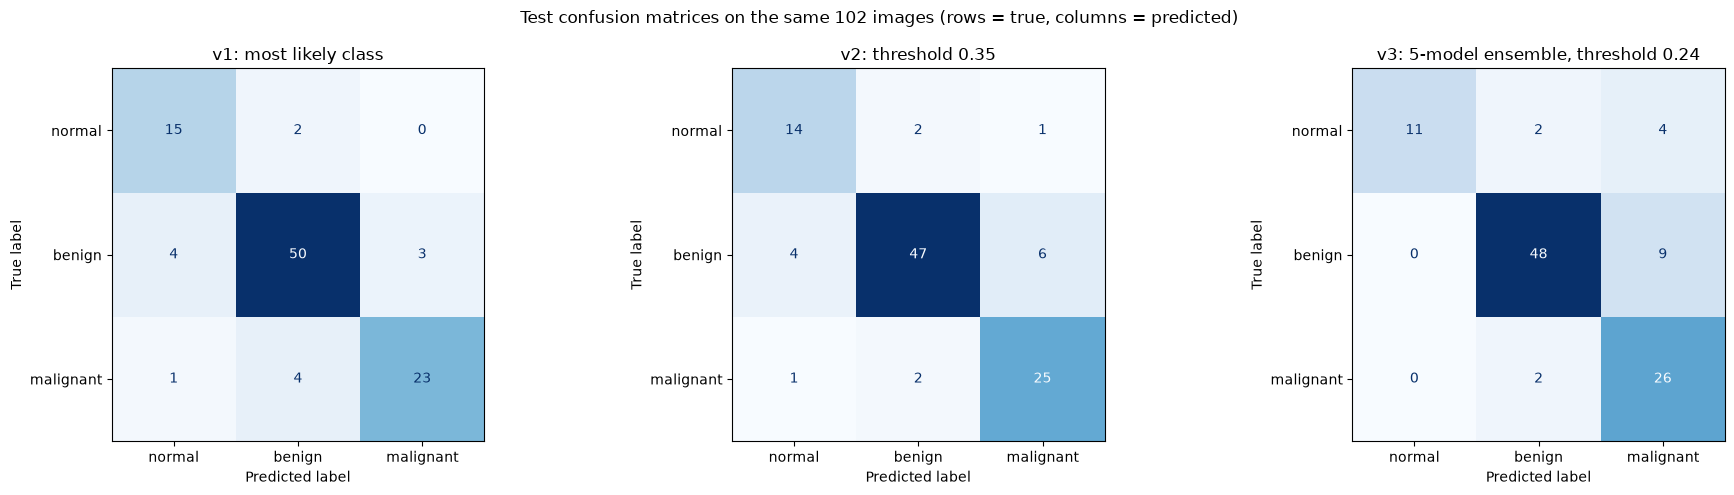

In [75]:
def archived_predictions(version_dir, column):
    """Probabilities and predicted classes from an archived run, for the current test images in the same order."""
    old = pd.read_csv(ARCHIVE_DIR / version_dir / 'classifier' / 'test_predictions.csv').set_index('image_path')
    old = old.loc[test_df['image_path']]
    old_probs = old[[f'prob_{c}' for c in CLASSES]].values
    old_probs = old_probs / old_probs.sum(axis=1, keepdims=True)   # v3: saved rounded to 4 decimals; make each row sum to 1 again
    return old_probs, old[column].map(CLASSES.index).values


v1_probs, y_pred_v1 = archived_predictions('v2_postprocessing', 'predicted_v1')     # v1 = most likely class
v2_probs, y_pred_v2 = archived_predictions('v2_postprocessing', 'predicted')        # v2 = threshold 0.35

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (title, pred) in zip(axes, [('v1: most likely class', y_pred_v1),
                                    ('v2: threshold 0.35', y_pred_v2),
                                    (f'v3: 5-model ensemble, threshold {MALIGNANT_THRESHOLD:.2f}', y_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=CLASSES).plot(cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(title)

plt.suptitle(f'Test confusion matrices on the same {len(y_true)} images (rows = true, columns = predicted)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

### Our two questions

1. **Tumour or not:** P(tumour) = P(benign) + P(malignant), called tumour when it's 0.5 or more.
   - **Sensitivity:** % of tumours found.
   - **Specificity:** % of normal scans correctly called normal.
2. **Malignant or not:** **malignant recall** = % of cancers caught. This is the most important number, because missing a cancer is the worst mistake.

**ROC-AUC** measures how well the probabilities separate the classes, from 0.5 (random guessing) to 1.0 (perfect).

The **95% ranges** come from a bootstrap: 1,000 new test sets of the same size are drawn by picking test images at random (with replacement), and the middle 95% of the scores is kept. All versions use the same 1,000 draws, so they're compared on the same luck.

In [76]:
def compute_metrics(y_true, probs, y_pred):
    """All test scores for one set of probabilities and predicted class numbers."""
    is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]
    is_malignant, p_malignant = y_true == 2, probs[:, 2]
    pred_tumour, pred_malignant = p_tumour >= 0.5, y_pred == 2
    return {
        'accuracy': float((y_pred == y_true).mean()),
        'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / max(is_tumour.sum(), 1)),
        'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / max((~is_tumour).sum(), 1)),
        'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
        'malignant_recall': float((pred_malignant & is_malignant).sum() / max(is_malignant.sum(), 1)),
        'malignant_precision': float((pred_malignant & is_malignant).sum() / max(pred_malignant.sum(), 1)),
        'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
        'roc_auc_3_class': float(roc_auc_score(y_true, probs, multi_class='ovr', labels=[0, 1, 2])),
    }


def confidence_range(y_true, probs, y_pred, n=N_BOOTSTRAP):
    """95% range of every score: re-draw the test set n times (same size, with replacement) and re-score it."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = []
    for _ in range(n):
        pick = rng.integers(0, len(y_true), size=len(y_true))     # random test set of the same size
        scores.append(compute_metrics(y_true[pick], probs[pick], y_pred[pick]))
    scores = pd.DataFrame(scores)
    return scores.quantile(0.025), scores.quantile(0.975)


versions = {'v1': (v1_probs, y_pred_v1), 'v2': (v2_probs, y_pred_v2), 'v3': (probs, y_pred)}
table = {}
for name, (version_probs, version_pred) in versions.items():
    scores = compute_metrics(y_true, version_probs, version_pred)
    low, high = confidence_range(y_true, version_probs, version_pred)
    table[name] = pd.Series(scores)
    table[f'{name} 95% range'] = pd.Series({k: f'{low[k]:.3f} - {high[k]:.3f}' for k in scores})
    if name == 'v3':
        metrics = scores
        metrics['confidence_95'] = {k: [round(float(low[k]), 4), round(float(high[k]), 4)] for k in scores}

comparison = pd.DataFrame(table)
comparison.to_csv(OUTPUT_DIR / 'metrics_by_version.csv')
(OUTPUT_DIR / 'metrics_v1_vs_v2.csv').unlink(missing_ok=True)     # v3: replaced by metrics_by_version.csv
comparison.round(3)

,v1,v1 95% range,v2,v2 95% range,v3,v3 95% range
accuracy,0.863,0.784 - 0.922,0.843,0.765 - 0.902,0.833,0.755 - 0.902
tumour_sensitivity,0.953,0.902 - 0.989,0.953,0.902 - 0.989,0.988,0.962 - 1.000
tumour_specificity,0.824,0.632 - 1.000,0.824,0.632 - 1.000,0.706,0.467 - 0.920
tumour_roc_auc,0.974,0.945 - 0.996,0.974,0.945 - 0.996,0.986,0.964 - 0.999
malignant_recall,0.821,0.667 - 0.958,0.893,0.771 - 1.000,0.929,0.812 - 1.000
malignant_precision,0.885,0.739 - 1.000,0.781,0.630 - 0.909,0.667,0.500 - 0.810
malignant_roc_auc,0.971,0.937 - 0.993,0.971,0.937 - 0.993,0.976,0.945 - 0.997
roc_auc_3_class,0.963,0.935 - 0.985,0.963,0.935 - 0.985,0.979,0.959 - 0.993


### Single models vs the ensemble

Each fold model on its own (with the same tuned threshold) compared with their average. If the ensemble is at least as good as the best single model and better than their average, combining them helps.

In [77]:
rows = {}
for fold in range(N_FOLDS):
    fold_probs = fold_test_probs[fold]
    rows[f'model {fold}'] = compute_metrics(y_true, fold_probs, decide(fold_probs, MALIGNANT_THRESHOLD))
single = pd.DataFrame(rows).T
single.loc['average of single models'] = single.mean()
single.loc['ensemble (v3)'] = pd.Series({k: v for k, v in metrics.items() if k != 'confidence_95'})
single.to_csv(OUTPUT_DIR / 'single_vs_ensemble.csv')
single[['accuracy', 'malignant_recall', 'malignant_precision', 'malignant_roc_auc', 'tumour_sensitivity', 'tumour_specificity']].round(3)

,accuracy,malignant_recall,malignant_precision,malignant_roc_auc,tumour_sensitivity,tumour_specificity
model 0,0.843,0.786,0.786,0.925,0.976,0.765
model 1,0.814,0.929,0.650,0.962,1.000,0.588
model 2,0.784,0.929,0.591,0.960,1.000,0.647
model 3,0.833,0.750,0.750,0.938,0.988,0.647
model 4,0.784,0.786,0.647,0.928,0.965,0.647
average of single models,0.812,0.836,0.685,0.943,0.986,0.659
ensemble (v3),0.833,0.929,0.667,0.976,0.988,0.706


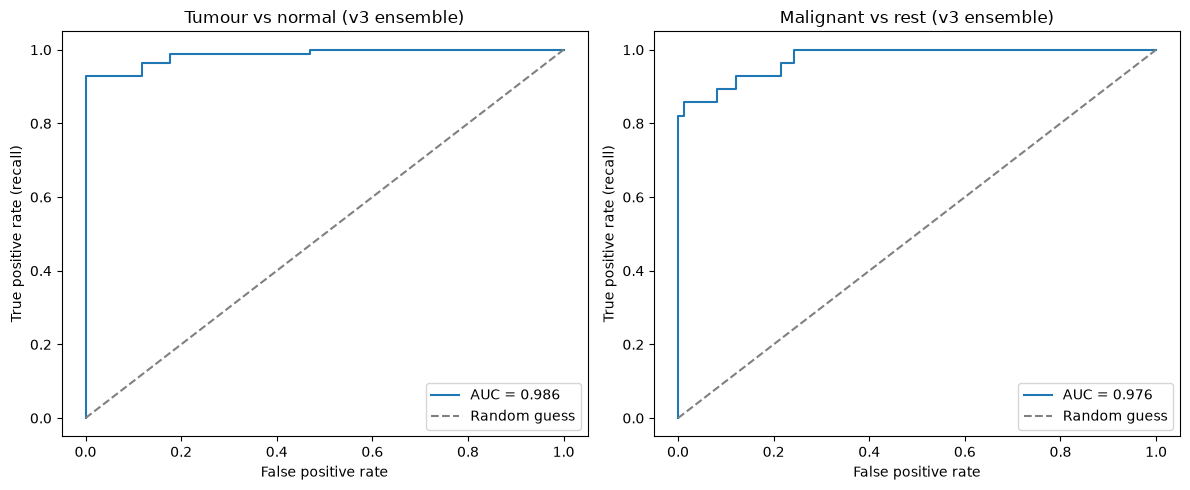

In [78]:
is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]       # 1. Tumour vs normal
is_malignant, p_malignant = y_true == 2, probs[:, 2]              # 2. Malignant vs the rest

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, truth, score, auc) in zip(axes, [
    ('Tumour vs normal', is_tumour, p_tumour, metrics['tumour_roc_auc']),
    ('Malignant vs rest', is_malignant, p_malignant, metrics['malignant_roc_auc']),
]):
    false_pos_rate, true_pos_rate, _ = roc_curve(truth, score)
    ax.plot(false_pos_rate, true_pos_rate, label=f'AUC = {auc:.3f}')
    ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random guess')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate (recall)')
    ax.set_title(f'{title} (v3 ensemble)')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curves.png', dpi=120, bbox_inches='tight')
plt.show()

### Shortcut check: images with vs without markers

If accuracy is much higher on images with markers, the model may be using the markers instead of the tissue.

In [79]:
marker_check = results.groupby('has_markers')['correct'].agg(accuracy='mean', images='count')
metrics['accuracy_with_markers'] = float(marker_check['accuracy'].get(True, float('nan')))
metrics['accuracy_without_markers'] = float(marker_check['accuracy'].get(False, float('nan')))
metrics['malignant_threshold'] = MALIGNANT_THRESHOLD     # the decision rule used for these results
metrics['n_models'] = N_FOLDS
metrics['test_images'] = int(len(y_true))

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))   # save all test results (v3)
marker_check.round(3)

,accuracy,images
has_markers,,
False,0.842,38
True,0.828,64


## 9. Grad-CAM: where is the model looking?

Grad-CAM colours the parts of the image that pushed the model towards its prediction (red = most important). The **green outline** is the real lesion from the mask. A good model should light up inside or around the green outline, not on markers or empty areas.

**v3:** the heatmap is the average of the 5 fold models' heatmaps.

In [80]:
def grad_cam(model, image_tensor, class_index):
    """Heatmap (IMAGE_SIZE x IMAGE_SIZE, 0 to 1) of the regions that support class_index."""
    saved = {}
    hook = model.layer4.register_forward_hook(lambda module, inp, out: saved.update(features=out))   # last conv block
    logits = model(image_tensor.unsqueeze(0).to(device))
    hook.remove()

    features = saved['features']                                          # shape (1, 512, 8, 8)
    gradients = torch.autograd.grad(logits[0, class_index], features)[0]  # how each feature affects the score
    weights = gradients.mean(dim=(2, 3), keepdim=True)                    # importance of each of the 512 channels
    cam = F.relu((weights * features).sum(dim=1, keepdim=True))           # weighted sum, keep positive evidence
    cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)                                       # scale to 0..1


def load_padded_mask(mask_paths):
    """Merge an image's masks and pad/resize them exactly like the image."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    merged = Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)
    return np.array(pad_to_square(merged)) > 127

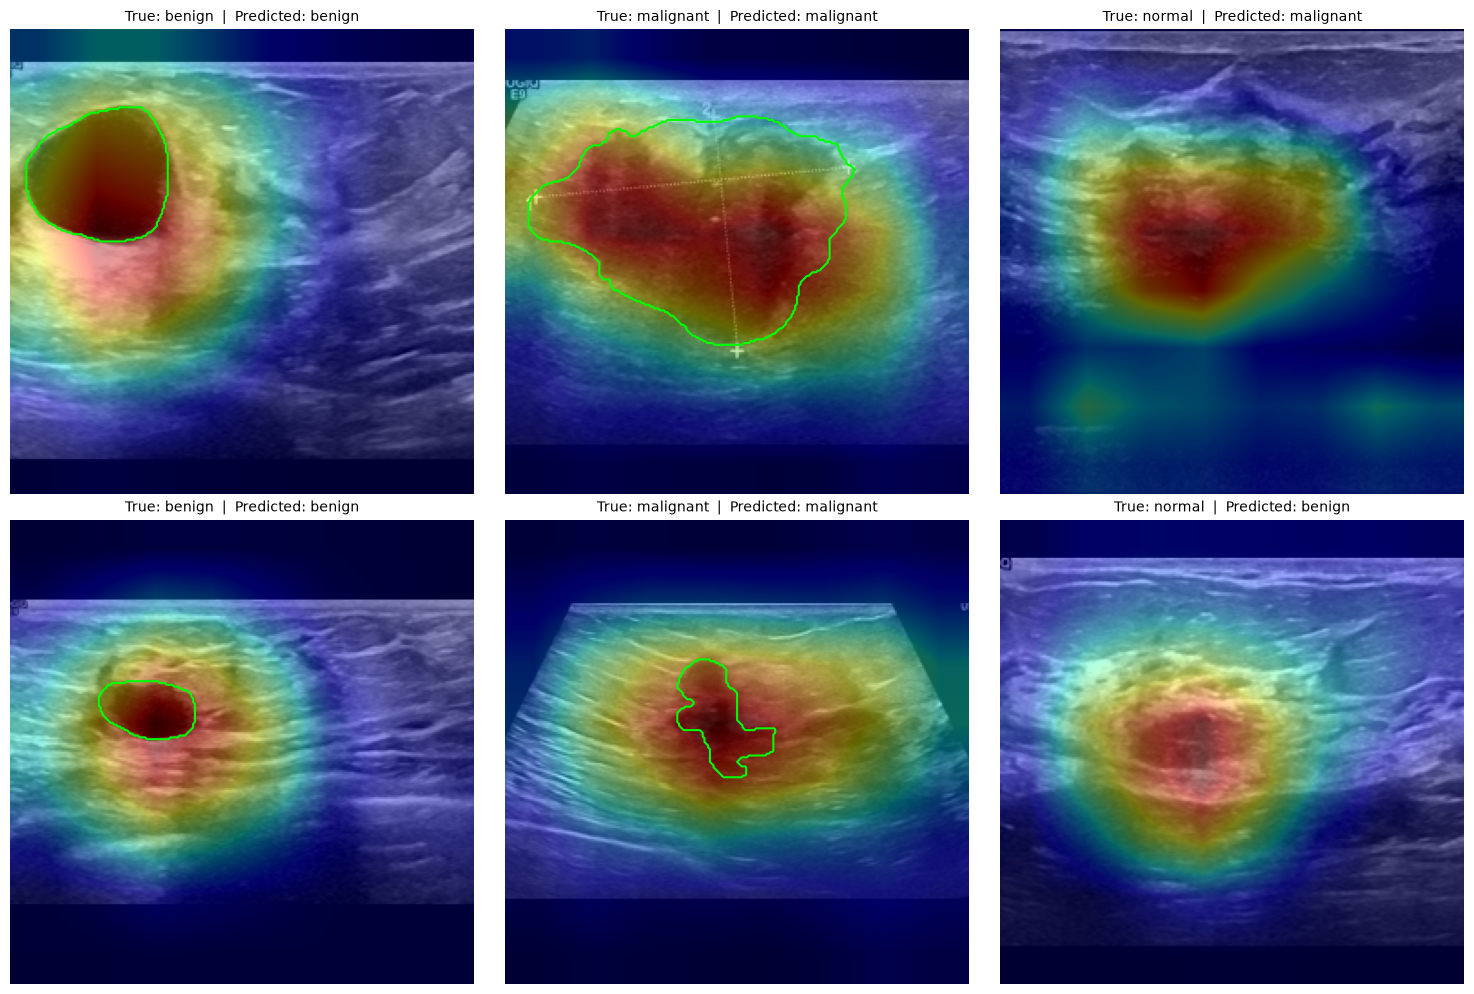

In [81]:
examples = test_df.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, row in zip(axes.T.flat, examples.itertuples()):
    image = pad_to_square(Image.open(DATA_DIR / row.image_path))
    tensor = eval_transform(image)

    with torch.no_grad():
        image_probs = np.mean([torch.softmax(net(tensor.unsqueeze(0).to(device)), dim=1).cpu().numpy()
                               for net in fold_models], axis=0)                  # v3: ensemble probabilities
    prediction = int(decide(image_probs, MALIGNANT_THRESHOLD)[0])
    cam = np.mean([grad_cam(net, tensor, prediction) for net in fold_models], axis=0)   # v3: average heatmap
    cam = cam / (cam.max() + 1e-8)

    ax.imshow(image, cmap='gray')
    ax.imshow(cam, cmap='jet', alpha=0.4)                                         # Grad-CAM heatmap
    mask = load_padded_mask(row.mask_paths)
    if mask.any():
        ax.contour(mask, levels=[0.5], colors='lime', linewidths=1.5)            # real lesion outline
    ax.set_title(f'True: {row.label}  |  Predicted: {CLASSES[prediction]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gradcam_examples.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Save the config

The app needs to rebuild exactly the same models and preprocess uploaded images exactly the same way. Everything it needs is stored here.

In [82]:
config = {
    'model_name': f'ResNet18 classifier ({N_FOLDS}-model ensemble)',
    'architecture': 'resnet18',
    'model_files': [f'model_fold{fold}.pt' for fold in range(N_FOLDS)],   # v3: the app averages these models
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'malignant_threshold': MALIGNANT_THRESHOLD,
    'threshold_tuned_on': f'out-of-fold predictions ({len(pool_df)} images, {N_FOLDS}-fold cross-validation)',
    'decision_rule': 'average the models\' probabilities; malignant if P(malignant) >= malignant_threshold, '
                     'else the more likely of normal / benign',
    'gradcam_layer': 'layer4',
    'best_epochs': [int(e) for e in best_epochs],
    'epochs_trained': history.groupby('fold').size().astype(int).tolist(),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'images': {'cross_validation': len(pool_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M') if TRAIN else previous_config['trained_on'],
    'evaluated_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {path.name:26s} {path.stat().st_size / 1024:8.1f} KB')

Saved files:
  config.json                     1.1 KB
  confusion_matrix.png           61.3 KB
  gradcam_examples.png         1605.8 KB
  history.csv                     5.1 KB
  metrics.json                    1.0 KB
  metrics_by_version.csv          0.9 KB
  model_fold0.pt              43740.4 KB
  model_fold1.pt              43740.4 KB
  model_fold2.pt              43740.4 KB
  model_fold3.pt              43740.4 KB
  model_fold4.pt              43740.4 KB
  oof_predictions.csv            35.5 KB
  roc_curves.png                 43.3 KB
  single_vs_ensemble.csv          1.2 KB
  test_predictions.csv            7.3 KB
  threshold_tuning.png           41.1 KB
  training_curves.png           200.8 KB


## 11. Check: reload and predict, the way the app will

This rebuilds the models from the saved files alone and predicts one test image. The probabilities should match the saved test prediction for that image. If it works here, the app can use the same two functions.

In [83]:
def load_classifier(folder):
    """Rebuild the trained fold models from config.json and model_fold*.pt."""
    config = json.loads((folder / 'config.json').read_text())
    nets = []
    for file_name in config['model_files']:
        net = models.resnet18(weights=None)                              # same architecture, no download
        net.fc = nn.Linear(net.fc.in_features, len(config['classes']))
        net.load_state_dict(torch.load(folder / file_name, map_location='cpu'))
        net.eval()
        nets.append(net)
    return nets, config


def predict(nets, config, image):
    """Class probabilities (averaged over the models) and predicted class for one PIL image."""
    size = config['image_size']
    preprocess = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(config['normalize_mean'], config['normalize_std']),
    ])
    tensor = preprocess(ImageOps.pad(image.convert('L'), (size, size), color=0)).unsqueeze(0)
    with torch.no_grad():
        probabilities = np.mean([torch.softmax(net(tensor), dim=1)[0].numpy() for net in nets], axis=0)

    # Malignant if P(malignant) >= the tuned threshold, otherwise the more likely of normal / benign
    if probabilities[2] >= config['malignant_threshold']:
        predicted = 'malignant'
    else:
        predicted = config['classes'][int(probabilities[:2].argmax())]
    return dict(zip(config['classes'], probabilities.round(4).tolist())), predicted


nets, saved_config = load_classifier(OUTPUT_DIR)
sample = results[results['label'] == 'malignant'].iloc[0]
probabilities, predicted = predict(nets, saved_config, Image.open(DATA_DIR / sample['image_path']))
print('Image:          ', sample['image_path'])
print('True label:     ', sample['label'])
print('Probabilities:  ', probabilities)
print('Saved test row: ', {c: sample[f'prob_{c}'] for c in CLASSES}, '(should match closely)')
print('Predicted:      ', predicted)

Image:           malignant/malignant (1).png
True label:      malignant
Probabilities:   {'normal': 0.020999999716877937, 'benign': 0.16750000417232513, 'malignant': 0.8115000128746033}
Saved test row:  {'normal': np.float32(0.021), 'benign': np.float32(0.1675), 'malignant': np.float32(0.8115)} (should match closely)
Predicted:       malignant


## 12. Key findings (v3)

*Fill in after running the notebook.*

- **Fold models (best epochs):**
- **Malignant threshold (out-of-fold):**
- **v1 → v2 → v3 malignant recall / precision:**
- **Ensemble vs single models:**
- **Markers (accuracy with vs without):**